In [1]:
import os
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

for root, dirs, files in os.walk("/kaggle/input"):
    print(root, "| folders:", len(dirs), "| files:", len(files))
    if len(files) > 0:
        print("example:", files[:3])
        break

Device: cuda
GPU: Tesla T4
/kaggle/input | folders: 1 | files: 0
/kaggle/input/datasets | folders: 1 | files: 0
/kaggle/input/datasets/zuozhaorui | folders: 1 | files: 0
/kaggle/input/datasets/zuozhaorui/celeba | folders: 1 | files: 0
/kaggle/input/datasets/zuozhaorui/celeba/img_align_celeba | folders: 1 | files: 202599
example: ['000001.jpg', '000002.jpg', '000003.jpg']


In [2]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.utils as vutils
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = "/kaggle/input/datasets/zuozhaorui/celeba/img_align_celeba/img_align_celeba"
IMAGE_SIZE = 64
BATCH_SIZE = 128
NUM_IMAGES = 30000
NUM_WORKERS = 2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [3]:
transform = T.Compose([
    T.CenterCrop(178),                 
    T.Resize(IMAGE_SIZE),             
    T.ToTensor(),                      
    T.Normalize((0.5, 0.5, 0.5),      
                (0.5, 0.5, 0.5)),
])

class CelebADataset(Dataset):
    def __init__(self, root_dir, transform, num_images):
        all_files = sorted(os.listdir(root_dir))
        self.files = all_files[:num_images]
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        path = os.path.join(self.root_dir, self.files[idx])
        image = Image.open(path).convert("RGB")
        return self.transform(image)

dataset = CelebADataset(DATA_DIR, transform, NUM_IMAGES)
dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    drop_last=True,
)

print("Dataset size:", len(dataset))
print("Number of batches:", len(dataloader))

Dataset size: 30000
Number of batches: 234


Batch shape: torch.Size([128, 3, 64, 64])
Min: -1.0 Max: 1.0


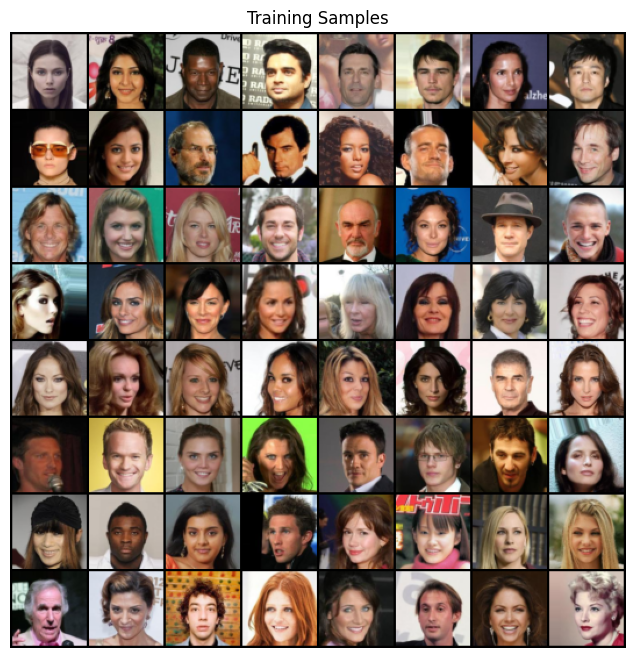

In [4]:
batch = next(iter(dataloader))
print("Batch shape:", batch.shape)
print("Min:", batch.min().item(), "Max:", batch.max().item())

plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("Training Samples")
grid = vutils.make_grid(batch[:64], padding=2, normalize=True)
plt.imshow(np.transpose(grid.cpu().numpy(), (1, 2, 0)))
plt.show()

In [5]:
LATENT_DIM = 100     
NGF = 64            
NDF = 64             
NUM_CHANNELS = 3    

def weights_init(m):
    """Initialize weights from a normal distribution (DCGAN paper)."""
    classname = m.__class__.__name__
    if classname.find("Conv") != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find("BatchNorm") != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

In [6]:
class Generator(nn.Module):
    def __init__(self, latent_dim, ngf, num_channels):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, ngf * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(True),

            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),

            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),

            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),

            nn.ConvTranspose2d(ngf, num_channels, 4, 2, 1, bias=False),
            nn.Tanh(),   
        )

    def forward(self, z):
        return self.net(z)

In [7]:
class Discriminator(nn.Module):
    def __init__(self, ndf, num_channels):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(num_channels, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(ndf * 4, ndf * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 8),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False),
            nn.Sigmoid(),   
        )

    def forward(self, x):
        return self.net(x).view(-1)

In [8]:
netG = Generator(LATENT_DIM, NGF, NUM_CHANNELS).to(device)
netD = Discriminator(NDF, NUM_CHANNELS).to(device)

netG.apply(weights_init)
netD.apply(weights_init)

test_noise = torch.randn(16, LATENT_DIM, 1, 1, device=device)
fake_images = netG(test_noise)
scores = netD(fake_images)

print("Noise shape:", test_noise.shape)
print("Generated images shape:", fake_images.shape)
print("Discriminator output shape:", scores.shape)
print("Generator params:", sum(p.numel() for p in netG.parameters()))
print("Discriminator params:", sum(p.numel() for p in netD.parameters()))

Noise shape: torch.Size([16, 100, 1, 1])
Generated images shape: torch.Size([16, 3, 64, 64])
Discriminator output shape: torch.Size([16])
Generator params: 3576704
Discriminator params: 2765568


In [9]:
import time

NUM_EPOCHS = 30
LR = 0.0002
BETA1 = 0.5
SAVE_EVERY = 5   

criterion = nn.BCELoss()

optimizerD = torch.optim.Adam(netD.parameters(), lr=LR, betas=(BETA1, 0.999))
optimizerG = torch.optim.Adam(netG.parameters(), lr=LR, betas=(BETA1, 0.999))

fixed_noise = torch.randn(64, LATENT_DIM, 1, 1, device=device)

REAL_LABEL = 1.0
FAKE_LABEL = 0.0

G_losses = []
D_losses = []
img_list = []       
os.makedirs("/kaggle/working/samples", exist_ok=True)

In [10]:
from tqdm.auto import tqdm

pil_transform = T.Compose([
    T.CenterCrop(178),
    T.Resize(IMAGE_SIZE),
])

def load_images_to_memory(root_dir, num_images):
    files = sorted(os.listdir(root_dir))[:num_images]
    tensors = []
    for name in tqdm(files):
        img = Image.open(os.path.join(root_dir, name)).convert("RGB")
        img = pil_transform(img)
        arr = torch.from_numpy(np.array(img)).permute(2, 0, 1)
        tensors.append(arr)
    return torch.stack(tensors)

data_cpu = load_images_to_memory(DATA_DIR, NUM_IMAGES)
data_gpu = data_cpu.to(device)   
N = data_gpu.size(0)
print("Loaded:", data_gpu.shape, data_gpu.dtype)

  0%|          | 0/30000 [00:00<?, ?it/s]

Loaded: torch.Size([30000, 3, 64, 64]) torch.uint8


In [11]:
n_batches = N // BATCH_SIZE
start_time = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_g, epoch_d = 0.0, 0.0
    perm = torch.randperm(N, device=device)

    for i in range(n_batches):
        idx = perm[i * BATCH_SIZE:(i + 1) * BATCH_SIZE]
        real_images = data_gpu[idx].float() / 127.5 - 1.0   
        b_size = real_images.size(0)

        netD.zero_grad()

        label_real = torch.full((b_size,), REAL_LABEL, device=device)
        output_real = netD(real_images)
        loss_d_real = criterion(output_real, label_real)
        loss_d_real.backward()

        noise = torch.randn(b_size, LATENT_DIM, 1, 1, device=device)
        fake_images = netG(noise)
        label_fake = torch.full((b_size,), FAKE_LABEL, device=device)
        output_fake = netD(fake_images.detach())
        loss_d_fake = criterion(output_fake, label_fake)
        loss_d_fake.backward()

        loss_d = loss_d_real + loss_d_fake
        optimizerD.step()

        netG.zero_grad()
        label_gen = torch.full((b_size,), REAL_LABEL, device=device)
        output_gen = netD(fake_images)
        loss_g = criterion(output_gen, label_gen)
        loss_g.backward()
        optimizerG.step()

        G_losses.append(loss_g.item())
        D_losses.append(loss_d.item())
        epoch_g += loss_g.item()
        epoch_d += loss_d.item()

    elapsed = time.time() - start_time
    print(f"Epoch [{epoch}/{NUM_EPOCHS}] | "
          f"Loss_D: {epoch_d / n_batches:.4f} | "
          f"Loss_G: {epoch_g / n_batches:.4f} | "
          f"Time: {elapsed:.0f}s", flush=True)

    if epoch == 1 or epoch % SAVE_EVERY == 0:
        netG.eval()
        with torch.no_grad():
            fake = netG(fixed_noise).detach().cpu()
        netG.train()
        grid = vutils.make_grid(fake, padding=2, normalize=True)
        img_list.append((epoch, grid))
        vutils.save_image(fake, f"/kaggle/working/samples/epoch_{epoch:03d}.png",
                          nrow=8, normalize=True, padding=2)

torch.save(netG.state_dict(), "/kaggle/working/generator.pth")
torch.save(netD.state_dict(), "/kaggle/working/discriminator.pth")
print("Training finished. Models saved.")

Epoch [1/30] | Loss_D: 0.6109 | Loss_G: 9.4319 | Time: 45s
Epoch [2/30] | Loss_D: 0.6234 | Loss_G: 4.5474 | Time: 88s
Epoch [3/30] | Loss_D: 0.6099 | Loss_G: 5.2948 | Time: 131s
Epoch [4/30] | Loss_D: 0.6128 | Loss_G: 5.1023 | Time: 173s
Epoch [5/30] | Loss_D: 0.6352 | Loss_G: 5.0210 | Time: 216s
Epoch [6/30] | Loss_D: 0.6047 | Loss_G: 4.7187 | Time: 259s
Epoch [7/30] | Loss_D: 0.5972 | Loss_G: 4.2484 | Time: 302s
Epoch [8/30] | Loss_D: 0.6294 | Loss_G: 3.9149 | Time: 344s
Epoch [9/30] | Loss_D: 0.6370 | Loss_G: 3.7932 | Time: 387s
Epoch [10/30] | Loss_D: 0.6246 | Loss_G: 3.6770 | Time: 429s
Epoch [11/30] | Loss_D: 0.6388 | Loss_G: 3.6166 | Time: 472s
Epoch [12/30] | Loss_D: 0.6622 | Loss_G: 3.4644 | Time: 515s
Epoch [13/30] | Loss_D: 0.6447 | Loss_G: 3.2204 | Time: 558s
Epoch [14/30] | Loss_D: 0.6896 | Loss_G: 3.0377 | Time: 600s
Epoch [15/30] | Loss_D: 0.7188 | Loss_G: 2.9192 | Time: 643s
Epoch [16/30] | Loss_D: 0.7146 | Loss_G: 2.8194 | Time: 686s
Epoch [17/30] | Loss_D: 0.7031 | Lo

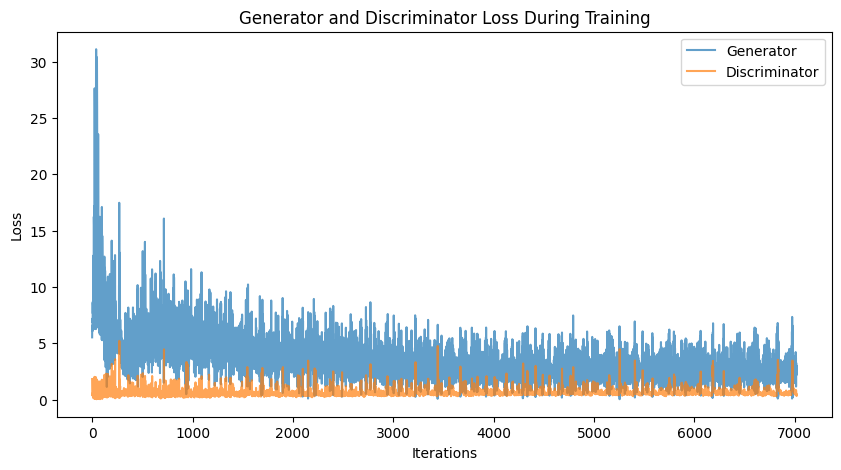

In [12]:
plt.figure(figsize=(10, 5))
plt.title("Generator and Discriminator Loss During Training")
plt.plot(G_losses, label="Generator", alpha=0.7)
plt.plot(D_losses, label="Discriminator", alpha=0.7)
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.legend()
plt.show()

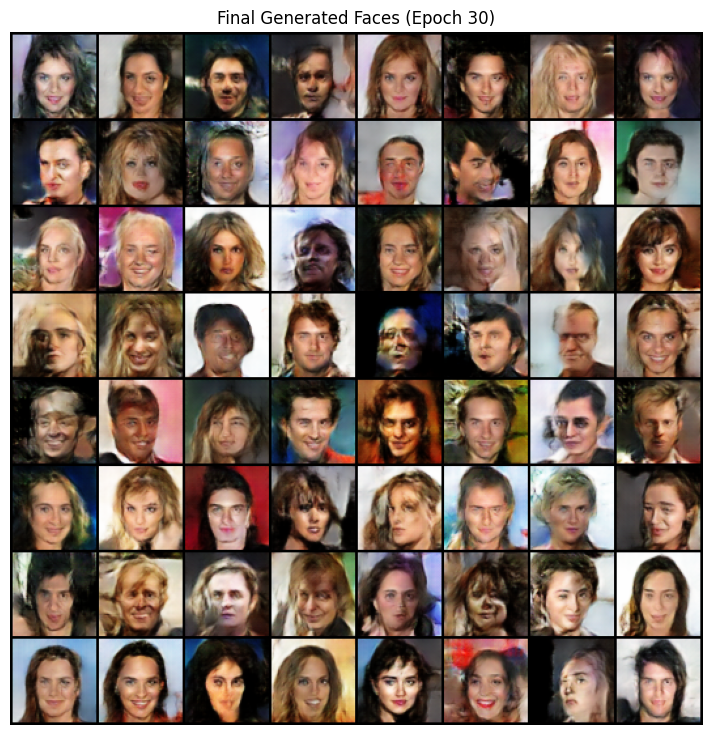

In [13]:
netG.eval()
with torch.no_grad():
    final_fake = netG(fixed_noise).detach().cpu()

plt.figure(figsize=(9, 9))
plt.axis("off")
plt.title("Final Generated Faces (Epoch 30)")
grid = vutils.make_grid(final_fake, nrow=8, padding=2, normalize=True)
plt.imshow(np.transpose(grid.numpy(), (1, 2, 0)))
plt.show()

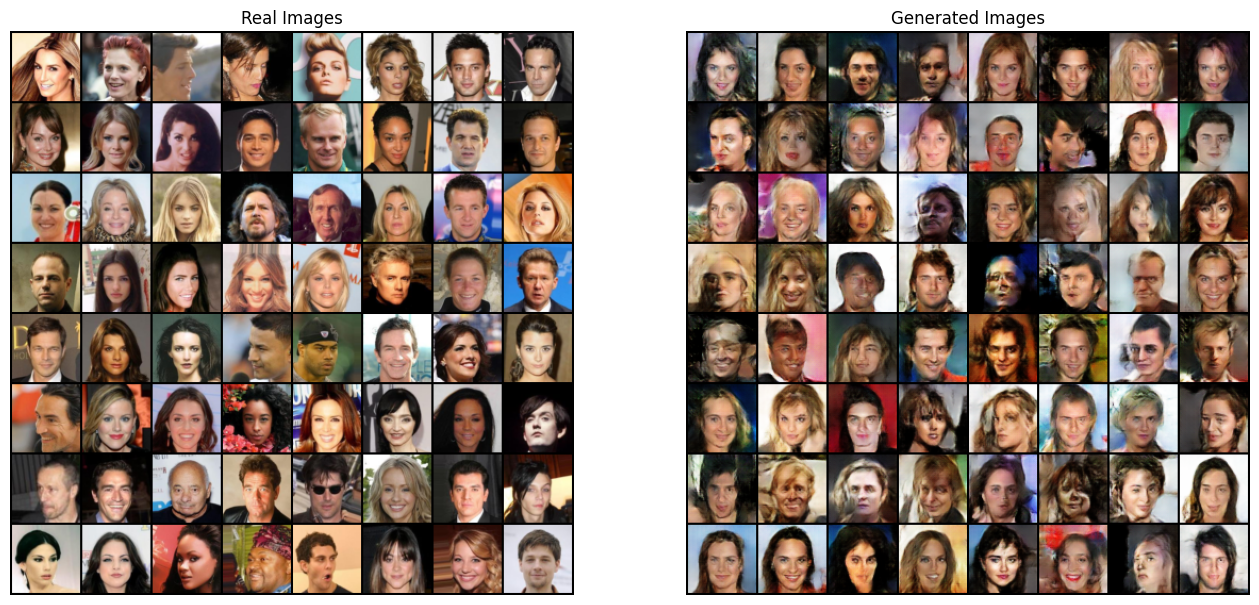

In [14]:
real_batch = data_gpu[:64].float().div(127.5).sub(1.0).cpu()

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].axis("off")
axes[0].set_title("Real Images")
axes[0].imshow(np.transpose(
    vutils.make_grid(real_batch, nrow=8, padding=2, normalize=True).numpy(), (1, 2, 0)))

axes[1].axis("off")
axes[1].set_title("Generated Images")
axes[1].imshow(np.transpose(
    vutils.make_grid(final_fake, nrow=8, padding=2, normalize=True).numpy(), (1, 2, 0)))
plt.show()

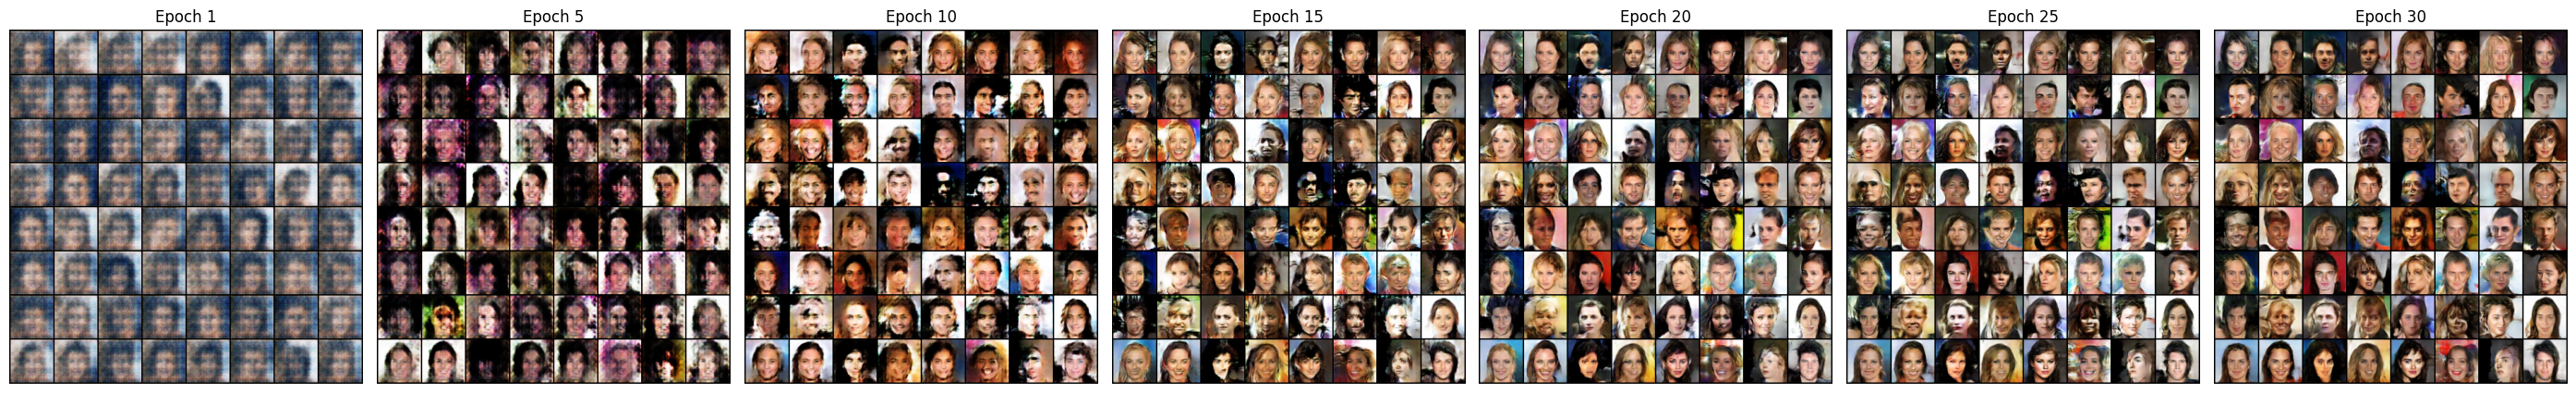

In [15]:
n = len(img_list)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 4.5))
for ax, (ep, g) in zip(axes, img_list):
    ax.axis("off")
    ax.set_title(f"Epoch {ep}")
    ax.imshow(np.transpose(g.numpy(), (1, 2, 0)))
plt.tight_layout()
plt.show()

In [16]:
os.makedirs("/kaggle/working/results", exist_ok=True)

plt.figure(figsize=(10, 5))
plt.title("Generator and Discriminator Loss During Training")
plt.plot(G_losses, label="Generator", alpha=0.7)
plt.plot(D_losses, label="Discriminator", alpha=0.7)
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.legend()
plt.savefig("/kaggle/working/results/loss_curves.png", dpi=150, bbox_inches="tight")
plt.close()

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].axis("off")
axes[0].set_title("Real Images")
axes[0].imshow(np.transpose(
    vutils.make_grid(real_batch, nrow=8, padding=2, normalize=True).numpy(), (1, 2, 0)))
axes[1].axis("off")
axes[1].set_title("Generated Images")
axes[1].imshow(np.transpose(
    vutils.make_grid(final_fake, nrow=8, padding=2, normalize=True).numpy(), (1, 2, 0)))
plt.savefig("/kaggle/working/results/real_vs_generated.png", dpi=150, bbox_inches="tight")
plt.close()

n = len(img_list)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 4.5))
for ax, (ep, g) in zip(axes, img_list):
    ax.axis("off")
    ax.set_title(f"Epoch {ep}")
    ax.imshow(np.transpose(g.numpy(), (1, 2, 0)))
plt.tight_layout()
plt.savefig("/kaggle/working/results/training_progress.png", dpi=150, bbox_inches="tight")
plt.close()

print(os.listdir("/kaggle/working/results"))

['loss_curves.png', 'training_progress.png', 'real_vs_generated.png']
